---

# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

*Eksperimen `knn_idea_combos`: semua kombinasi 8 ide perbaikan KNN, jarak dihitung di GPU.*

---

## Table of Contents

1. [**Initialization**](#1)
2. [**Kode Pendukung**](#2)
3. [**Delapan Ide**](#3)
4. [**Tahap A: Pilihan di Dalam Ide**](#4)
5. [**Tahap B: Semua Kombinasi**](#5)

---

# Initialization <a name="1"></a>

---

## Import Libraries

Jarak KNN dihitung dengan PyTorch di GPU agar ratusan kombinasi bisa dicoba cepat. Jalankan di Colab dengan runtime GPU (Runtime, Change runtime type, T4 GPU). Tanpa GPU notebook tetap jalan di CPU, tetapi jauh lebih lama.

GPU hanya dipakai untuk pencarian. Model final untuk submisi tetap KNN from scratch dengan NumPy.

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda NVIDIA L4


## Settings

- `BASE_FEATURES` dan `K_GRID`: fitur dan pilihan k dari `knn_selection_distance` (public 0,85505)
- `SEEDS`: seed 42 untuk memilih (pilihan di dalam ide dan k), seed 1 sampai 5 untuk menilai
- `P_OPTIONS`, `SCALER_OPTIONS`, `KERNEL_OPTIONS`: pilihan yang dicoba pada Tahap A
- `BATCH`: jumlah query per hitungan jarak di GPU, turunkan jika memori GPU tidak cukup

In [2]:
class Settings:
    TARGET = 'is_canceled'
    BASE_FEATURES = ['days_before_arrival', 'arrival_index', 'special_requests', 'nightly_rate_idr',
                     'booking_channel', 'arrival_dayofyear', 'total_nights', 'needs_parking']
    K_GRID = [11, 15, 19, 25, 31]
    SEEDS = [42, 1, 2, 3, 4, 5]
    CHECK_SEEDS = [1, 2, 3, 4, 5]
    P_OPTIONS = [0.5, 0.75, 1.25, 1.5]
    SCALER_OPTIONS = ['robust', 'minmax']
    KERNEL_OPTIONS = ['inv2', 'gauss']
    MIN_GAIN = 0.0005
    BATCH = 2048
    RESULT_PATH = 'knn_combo_results.csv'

## Load Dataset

Isi variabel `train` (dengan kolom `is_canceled`) sebagai DataFrame pada sel berikut. Kolom `id` dibaca sebagai teks. Data test tidak dibutuhkan di notebook ini.

In [3]:
train = pd.read_csv('train.csv')

len(train)

27373

---

# Kode Pendukung <a name="2"></a>

---

Preprocessing bersama kelompok dan fungsi validasi.

In [4]:
TARGET = 'is_canceled'


ID_COL = 'id'


CAT_COLS = ['meal_package', 'room_category', 'booking_channel']


# Buang baris duplikat persis (fitur dan target). Hanya untuk data train.
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)


# Ubah nilai yang tidak masuk akal (num_adults = 0) menjadi missing.
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df


# Tambah fitur turunan per baris, aman dipakai pada train dan test secara terpisah.
def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.day_of_week.astype(float)
    df['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df

In [5]:
# Confusion matrix biner dalam bentuk [[TN, FP], [FN, TP]].
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


# F1 untuk kelas 0 dan kelas 1, hasilnya [f1_0, f1_1].
def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])


# Macro F1, rata-rata F1 kedua kelas (metrik resmi kompetisi).
def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())


# Cari threshold dengan Macro F1 tertinggi, dipakai pada prediksi out-of-fold.
def best_threshold(y_true, proba, grid=None):
    if grid is None:
        grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])


# Bagi indeks menjadi k fold dengan proporsi kelas sama, hasilnya list (train_idx, val_idx).
def stratified_kfold(y, n_splits=5, seed=42):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

Data train dibersihkan, lalu semua fitur kandidat dihitung sekali:

- fitur turunan kelompok (`add_features`)
- `booking_index`: hari pemesanan, `arrival_index - days_before_arrival` (ide 3)
- `doy_sin`, `doy_cos`: posisi hari kedatangan pada lingkaran tahun (ide 1)

In [6]:
train = clean_train(train)
y = train[Settings.TARGET].to_numpy()
E = add_features(mark_invalid(train)).drop(columns=['id', Settings.TARGET])
E['booking_index'] = E['arrival_index'] - E['days_before_arrival']
E['doy_sin'] = np.sin(2 * np.pi * E['arrival_dayofyear'] / 365.25)
E['doy_cos'] = np.cos(2 * np.pi * E['arrival_dayofyear'] / 365.25)

POOL = [c for c in E.columns if c not in ('booking_index', 'doy_sin', 'doy_cos')]
FOLDS = {s: stratified_kfold(y, 5, s) for s in Settings.SEEDS}
E.shape

(27309, 27)

---

# Delapan Ide <a name="3"></a>

---

Setiap ide adalah satu perubahan terhadap KNN terbaik saat ini (8 fitur, standardisasi, Manhattan, distance voting `1/d`).

| No | Ide | Perubahan | Materi |
| --- | --- | --- | --- |
| 1 | Encoding siklus | `arrival_dayofyear` diganti `doy_sin` dan `doy_cos`, sehingga 31 Desember dan 1 Januari berdekatan | feature engineering |
| 2 | Jarak sadar missing | Fitur yang kosong di salah satu baris dilewati, lalu jarak diskalakan ulang ke jumlah fitur | di luar materi |
| 3 | Tanggal pemesanan | Tambah `booking_index` | feature engineering |
| 4 | Minkowski p | p dari Tahap A (p = 1 adalah Manhattan, p = 2 Euclidean) | jarak Minkowski |
| 5 | Scaling lain | robust (median, IQR) atau min-max, dari Tahap A | scaling |
| 6 | Jarak kategori VDM | Kategori diganti rate batalnya, jarak dua kategori = selisih rate | di luar materi |
| 7 | Kernel voting | `1/d²` atau Gaussian, dari Tahap A | di luar materi |
| 8 | Seleksi ulang fitur | Floating selection: setiap langkah menghapus atau menambah satu fitur | wrapper, materi |

### Konsep: Jarak Sadar Missing (ide 2, di luar materi)

Jarak biasa membutuhkan semua nilai, sehingga missing harus diisi dulu (median). Di sini, jika fitur f kosong pada query atau pada tetangga, bagian jarak dari fitur f dilewati, lalu jarak diskalakan ulang:

```
d(a, b) = (jumlah fitur / jumlah fitur yang terisi di keduanya) × Σ_f terisi |a_f - b_f|^p
```

Contoh: 8 fitur, `days_before_arrival` kosong pada query. Jarak dihitung dari 7 fitur lain lalu dikali 8/7, sehingga sebanding dengan jarak baris yang lengkap.

### Konsep: Value Difference Metric (ide 6, di luar materi)

Pada materi, dua kategori berbeda selalu berjarak 1. VDM memakai rate batal setiap kategori di data train: Online Travel Agent (36%) dan Offline Agent (30%) berjarak kecil, sedangkan Complimentary (0%) jauh dari keduanya. Selisih rate dibagi rentang rate agar jarak terbesar tetap 1.

### Konsep: Kernel Voting (ide 7, di luar materi)

Bobot suara tetangga: `1/d` (sekarang), `1/d²` (tetangga dekat jauh lebih menentukan), atau Gaussian `exp(-(d/h)²)` dengan `h` jarak tetangga ke-k.

## Fungsi KNN di GPU

- `build` membentuk matriks fitur satu fold sesuai konfigurasi `cfg`, semua statistik dari baris train fold saja
- `neighbors` menghitung jarak di GPU dan mengambil `K_MAX` tetangga terdekat
- `vote` menghitung probabilitas batal dengan kernel yang dipilih
- `run` menghasilkan macro F1 OOF untuk setiap k pada satu pembagian fold

In [7]:
K_MAX = max(Settings.K_GRID)


def feature_list(cfg):
    feats = list(cfg.get('features') or Settings.BASE_FEATURES)
    if cfg.get('cyclic') and 'arrival_dayofyear' in feats:
        i = feats.index('arrival_dayofyear')
        feats[i:i + 1] = ['doy_sin', 'doy_cos']
    if cfg.get('booking') and 'booking_index' not in feats:
        feats.append('booking_index')
    return feats


def build(cfg, tr):
    miss_aware, scaler = cfg.get('missing_aware', False), cfg.get('scaler', 'standard')
    cols, blocks = [], []
    for f in feature_list(cfg):
        x = E[f]
        if f in CAT_COLS:
            filled = x if miss_aware else x.fillna(x.iloc[tr].mode()[0])
            if cfg.get('vdm'):
                rate = pd.Series(y[tr]).groupby(filled.iloc[tr].to_numpy()).mean()
                span = (rate.max() - rate.min()) or 1.0
                v = filled.map(rate).astype(float)
                v = v.where(filled.isna() | v.notna(), y[tr].mean())
                cols.append((v / span).to_numpy())
                blocks.append([len(cols) - 1])
            else:
                start = len(cols)
                for level in sorted(filled.iloc[tr].dropna().unique()):
                    col = (filled == level).astype(float) * 0.5
                    cols.append(col.where(filled.notna(), np.nan).to_numpy())
                blocks.append(list(range(start, len(cols))))
            continue
        x = x.astype(float)
        if not miss_aware:
            x = x.fillna(x.iloc[tr].median())
        xt = x.iloc[tr]
        if scaler == 'standard':
            center, spread = xt.mean(), xt.std()
        elif scaler == 'robust':
            center, spread = xt.median(), xt.quantile(0.75) - xt.quantile(0.25)
        else:
            center, spread = xt.min(), xt.max() - xt.min()
        spread = spread if spread and spread > 0 else (xt.std() or 1.0)
        cols.append(((x - center) / spread).to_numpy())
        blocks.append([len(cols) - 1])
    return np.column_stack(cols).astype(np.float32), blocks


def neighbors(Xq, Xt, blocks, p, miss_aware, k):
    Xq = torch.tensor(Xq, device=DEVICE)
    Xt = torch.tensor(Xt, device=DEVICE)
    all_d, all_i = [], []
    for s in range(0, len(Xq), Settings.BATCH):
        q = Xq[s:s + Settings.BATCH]
        total = torch.zeros(len(q), len(Xt), device=DEVICE)
        count = torch.zeros_like(total) if miss_aware else None
        for b in blocks:
            part = torch.zeros_like(total)
            for j in b:
                diff = (q[:, j, None] - Xt[None, :, j]).abs()
                part += diff if p == 1 else diff ** p
            if miss_aware:
                ok = ~torch.isnan(part)
                total += torch.where(ok, part, torch.zeros_like(part))
                count += ok
            else:
                total += part
        if miss_aware:
            total *= len(blocks) / count.clamp(min=1)
        d, idx = torch.topk(total, k, dim=1, largest=False, sorted=True)
        all_d.append((d if p == 1 else d ** (1 / p)).cpu().numpy())
        all_i.append(idx.cpu().numpy())
    return np.vstack(all_d), np.vstack(all_i)


def vote(d, labels, k, kernel):
    d, labels = d[:, :k], labels[:, :k]
    if kernel == 'inv2':
        w = 1.0 / (d ** 2 + 1e-6)
    elif kernel == 'gauss':
        w = np.exp(-(d / (d[:, -1:] + 1e-6)) ** 2)
    else:
        w = 1.0 / (d + 1e-6)
    return (w * labels).sum(1) / w.sum(1)


def run(cfg, seed):
    p, kernel = cfg.get('p', 1), cfg.get('kernel', 'inv')
    oof = {k: np.zeros(len(y)) for k in Settings.K_GRID}
    for tr, va in FOLDS[seed]:
        X, blocks = build(cfg, tr)
        d, idx = neighbors(X[va], X[tr], blocks, p, cfg.get('missing_aware', False), K_MAX)
        labels = y[tr][idx]
        for k in Settings.K_GRID:
            oof[k][va] = vote(d, labels, k, kernel)
    return {k: best_threshold(y, o)[1] for k, o in oof.items()}

Baseline (KNN terbaik saat ini) pada seed 42. Harus sekitar 0,8411 pada k 19.

In [8]:
start = time.time()
base = run({}, 42)
print({k: round(v, 4) for k, v in base.items()}, f'{time.time() - start:.1f} detik')

{11: 0.8396, 15: 0.8408, 19: 0.8411, 25: 0.8404, 31: 0.84} 1.7 detik


---

# Tahap A: Pilihan di Dalam Ide <a name="4"></a>

---

Ide 4, 5, 7, dan 8 punya beberapa pilihan. Pilihan terbaik ditentukan dari seed 42, lalu dipakai sebagai versi "aktif" ide tersebut pada Tahap B.

`best42` mengambil skor terbaik (di antara `K_GRID`) pada seed 42.

In [9]:
def best42(cfg):
    return max(run(cfg, 42).values())


stage_a = {}
for name, options in [('p', Settings.P_OPTIONS), ('scaler', Settings.SCALER_OPTIONS), ('kernel', Settings.KERNEL_OPTIONS)]:
    scores = {o: round(best42({name: o}), 4) for o in options}
    stage_a[name] = max(scores, key=scores.get)
    print(name, scores, '-> pilih', stage_a[name])

p {0.5: 0.8416, 0.75: 0.8418, 1.25: 0.8399, 1.5: 0.8387} -> pilih 0.75
scaler {'robust': 0.8396, 'minmax': 0.8423} -> pilih minmax
kernel {'inv2': 0.8406, 'gauss': 0.8288} -> pilih inv2


Ide 8: floating selection dari 8 fitur. Setiap langkah mencoba menghapus satu fitur atau menambah satu fitur dari `POOL`, lalu mengambil perubahan terbaik selama naik minimal `MIN_GAIN`.

In [10]:
feats, best = list(Settings.BASE_FEATURES), max(base.values())
while True:
    start = time.time()
    moves = [('-', f, [g for g in feats if g != f]) for f in feats] + [('+', f, feats + [f]) for f in POOL if f not in feats]
    score, (op, f, new) = max(((best42({'features': m[2]}), m) for m in moves), key=lambda t: t[0])
    print(f'terbaik {op}{f} {score:.4f} (sekarang {best:.4f}), {time.time() - start:.0f} detik')
    if score - best < Settings.MIN_GAIN:
        break
    feats, best = new, score
stage_a['features'] = feats
stage_a

terbaik +arrival_month 0.8419 (sekarang 0.8411), 36 detik
terbaik +is_returning_guest 0.8421 (sekarang 0.8419), 38 detik


{'p': 0.75,
 'scaler': 'minmax',
 'kernel': 'inv2',
 'features': ['days_before_arrival',
  'arrival_index',
  'special_requests',
  'nightly_rate_idr',
  'booking_channel',
  'arrival_dayofyear',
  'total_nights',
  'needs_parking',
  'arrival_month']}

#### Insights

> Isi setelah run.

---

# Tahap B: Semua Kombinasi <a name="5"></a>

---

Semua 2⁸ = 256 kombinasi ide (termasuk baseline tanpa ide). Setiap kombinasi dijalankan pada 6 pembagian fold. k dipilih dari seed 42, lalu kombinasi diurutkan dari rata-rata seed 1 sampai 5, sehingga pemilihan tidak memakai fold yang sama dengan penilaian. Hasil disimpan ke `RESULT_PATH` setiap 16 kombinasi, sehingga run yang terputus bisa dilanjutkan.

In [11]:
IDEAS = {
    1: ('cyclic', True), 2: ('missing_aware', True), 3: ('booking', True), 4: ('p', stage_a['p']),
    5: ('scaler', stage_a['scaler']), 6: ('vdm', True), 7: ('kernel', stage_a['kernel']), 8: ('features', stage_a['features']),
}
combos = [c for r in range(9) for c in itertools.combinations(range(1, 9), r)]
label = lambda c: ''.join(map(str, c)) or 'baseline'

rows, start = [], time.time()
for n, c in enumerate(combos, 1):
    cfg = dict(IDEAS[i] for i in c)
    scores = {s: run(cfg, s) for s in Settings.SEEDS}
    k = max(scores[42], key=scores[42].get)
    rows.append(dict(ide=label(c), n_ide=len(c), k=k, seed42=round(scores[42][k], 4),
                     **{f'seed{s}': round(scores[s][k], 4) for s in Settings.CHECK_SEEDS},
                     mean_1_5=round(np.mean([scores[s][k] for s in Settings.CHECK_SEEDS]), 4)))
    if n % 16 == 0 or n == len(combos):
        pd.DataFrame(rows).to_csv(Settings.RESULT_PATH, index=False)
        print(f'{n}/{len(combos)} kombinasi, {time.time() - start:.0f} detik')

results = pd.DataFrame(rows)

16/256 kombinasi, 154 detik
32/256 kombinasi, 325 detik
48/256 kombinasi, 503 detik
64/256 kombinasi, 682 detik
80/256 kombinasi, 867 detik
96/256 kombinasi, 1024 detik
112/256 kombinasi, 1244 detik
128/256 kombinasi, 1393 detik
144/256 kombinasi, 1620 detik
160/256 kombinasi, 1778 detik
176/256 kombinasi, 2006 detik
192/256 kombinasi, 2196 detik
208/256 kombinasi, 2396 detik
224/256 kombinasi, 2596 detik
240/256 kombinasi, 2805 detik
256/256 kombinasi, 3033 detik


Sepuluh kombinasi terbaik, diurutkan dari rata-rata seed 1 sampai 5. `menang` adalah jumlah seed (dari 5) yang lebih baik dari baseline.

In [12]:
base_row = results.set_index('ide').loc['baseline']
seed_cols = [f'seed{s}' for s in Settings.CHECK_SEEDS]
results['selisih'] = (results['mean_1_5'] - base_row['mean_1_5']).round(4)
results['menang'] = (results[seed_cols].to_numpy() > base_row[seed_cols].to_numpy().astype(float)).sum(1)
results.sort_values('mean_1_5', ascending=False).head(10)

,ide,n_ide,k,seed42,seed1,seed2,seed3,seed4,seed5,mean_1_5,selisih,menang
110,1347,4,31,0.8454,0.8459,0.8448,0.8447,0.8461,0.8460,0.8455,0.0037,5
89,567,3,31,0.8443,0.8457,0.8450,0.8448,0.8459,0.8458,0.8454,0.0036,5
32,57,2,31,0.8440,0.8453,0.8446,0.8448,0.8458,0.8456,0.8452,0.0034,5
46,137,3,31,0.8438,0.8461,0.8452,0.8433,0.8451,0.8453,0.8450,0.0032,5
158,4567,4,31,0.8446,0.8454,0.8439,0.8439,0.8458,0.8454,0.8449,0.0031,5
75,347,3,31,0.8437,0.8447,0.8450,0.8437,0.8451,0.8455,0.8448,0.0030,5
78,357,3,31,0.8448,0.8452,0.8442,0.8436,0.8453,0.8446,0.8446,0.0028,5
84,457,3,31,0.8443,0.8450,0.8436,0.8438,0.8455,0.8452,0.8446,0.0028,5
189,13567,5,31,0.8442,0.8446,0.8438,0.8444,0.8457,0.8447,0.8446,0.0028,5
213,34567,5,31,0.8445,0.8448,0.8441,0.8435,0.8453,0.8448,0.8445,0.0027,5


Pengaruh setiap ide: rata-rata skor semua kombinasi yang memakai ide tersebut dikurangi rata-rata yang tidak memakainya.

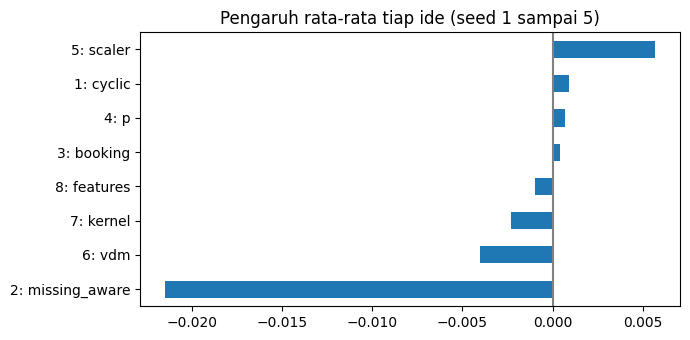

,0
5: scaler,0.0057
1: cyclic,0.0009
4: p,0.0007
3: booking,0.0004
8: features,-0.0010
7: kernel,-0.0023
6: vdm,-0.0040
2: missing_aware,-0.0215


In [13]:
effect = pd.Series({i: results.loc[results['ide'].str.contains(str(i)), 'mean_1_5'].mean()
                       - results.loc[~results['ide'].str.contains(str(i)), 'mean_1_5'].mean() for i in range(1, 9)})
effect.index = [f'{i}: {IDEAS[i][0]}' for i in effect.index]
effect.round(4).sort_values().plot.barh(figsize=(7, 3.5), title='Pengaruh rata-rata tiap ide (seed 1 sampai 5)')
plt.axvline(0, color='gray')
plt.tight_layout()
plt.show()
effect.round(4).sort_values(ascending=False)

Top 5 kombinasi disimpan terpisah.

In [14]:
top5 = results.sort_values('mean_1_5', ascending=False).head(5)
top5.to_csv('knn_combo_top5.csv', index=False)
top5

,ide,n_ide,k,seed42,seed1,seed2,seed3,seed4,seed5,mean_1_5,selisih,menang
110,1347,4,31,0.8454,0.8459,0.8448,0.8447,0.8461,0.8460,0.8455,0.0037,5
89,567,3,31,0.8443,0.8457,0.8450,0.8448,0.8459,0.8458,0.8454,0.0036,5
32,57,2,31,0.8440,0.8453,0.8446,0.8448,0.8458,0.8456,0.8452,0.0034,5
46,137,3,31,0.8438,0.8461,0.8452,0.8433,0.8451,0.8453,0.8450,0.0032,5
158,4567,4,31,0.8446,0.8454,0.8439,0.8439,0.8458,0.8454,0.8449,0.0031,5


#### Insights

> Isi setelah run.